## Module 3: Computational Drug Discovery Project

Liam Sunshine and Aymen Akram

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

### Disease Background

Obesity is defined in adults as a body mass index (BMI) of 30 kg/m² or greater and is associated with increased risks of cardiovascular disease, type 2 diabetes, certain cancers, and premature mortality (CDC, 2025). Its prevalence is influenced by multiple factors, including increased access to calorie-dense foods, sedentary lifestyles, genetic predisposition, and environmental conditions. Current treatments include dietary modifications, increased physical activity, behavioral interventions, bariatric surgery, and medications such as semaglutide, a GLP-1 receptor agonist that reduces appetite and promotes weight loss (NIDDK, n.d.). Although GLP-1 medications have demonstrated substantial effectiveness, challenges remain, including gastrointestinal side effects, treatment costs, nutritional concerns associated with reduced food intake, and weight regain following discontinuation (Wilding et al., 2021; Wilding et al., 2022). Maintaining adequate nutrition, cardiovascular exercise, and resistance training alongside pharmacological treatment may support long-term health and preservation of muscle mass. These limitations highlight the need for improved obesity treatments. Cavalitide, a proposed GLP-1 receptor agonist, is being investigated through computational modeling to evaluate its receptor-binding characteristics, pharmacokinetics, and potential advantages over existing medications.

## Task 1: Fit a receptor binding model for Cavalitide:


### Receptor-Binding Model and Methodology

To evaluate Cavalitide's pharmacodynamic properties, experimental concentration-response data were fitted to a competitive two-agonist model of GLP-1 receptor activation. The model accounts for both endogenous GLP-1 and Cavalitide binding to GLP1R.

The fraction of active receptors was modeled as:

$$
F_{act}=\frac{K_{d2}[GLP1]+K_{d1}[Drug]}{K_{d1}K_{d2}+K_{d2}[GLP1]+K_{d1}[Drug]}
$$

Here, $K_{d1}=0.17$ nM is the dissociation constant of endogenous GLP-1, $[GLP1]=0.015$ nM represents fasting GLP-1 concentration, and $K_{d2}$ is the fitted dissociation constant of Cavalitide or semaglutide. Experimental data provided for the project were fitted using brute-force optimization and SciPy's `curve_fit` function. Both methods minimized the sum of squared errors (SSE) between the observed and predicted receptor activation values.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Endogenous GLP-1 parameters (nM)
Kd1 = 0.17
L1 = 0.015

# Two-agonist receptor activation model
def Fact(L1, L2, Kd1, Kd2):
    return (Kd2 * L1 + Kd1 * L2) / (
        Kd1 * Kd2 + Kd2 * L1 + Kd1 * L2
    )

# Load experimental data
cavalitide_data = np.loadtxt(
    "cavalitide_data.csv", delimiter=",", skiprows=1
)
semaglutide_data = np.loadtxt(
    "semaglutide_data.csv", delimiter=",", skiprows=1
)

# Fit dissociation constants using two methods
def fit_drug(data):
    concentrations = data[:, 0]
    activation = data[:, 1]

    # Brute-force search
    candidates = np.logspace(-3, 2, 100)
    errors = [
        np.sum(
            (activation - Fact(L1, concentrations, Kd1, k))**2
        )
        for k in candidates
    ]
    Kd_brute = candidates[np.argmin(errors)]

    # Nonlinear least-squares fitting
    popt, pcov = curve_fit(
        lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
        concentrations,
        activation,
        p0=[0.1],
        bounds=(0, np.inf)
    )
    Kd_fit = popt[0]

    # Sum of squared errors
    SSE = np.sum(
        (activation - Fact(L1, concentrations, Kd1, Kd_fit))**2
    )

    return Kd_brute, Kd_fit, SSE

cav_brute, cav_Kd, cav_SSE = fit_drug(cavalitide_data)
sem_brute, sem_Kd, sem_SSE = fit_drug(semaglutide_data)

print("Cavalitide:")
print(f"  Brute-force Kd = {cav_brute:.4f} nM")
print(f"  Curve-fit Kd   = {cav_Kd:.4f} nM")
print(f"  SSE            = {cav_SSE:.5f}")

print("\nSemaglutide:")
print(f"  Brute-force Kd = {sem_brute:.4f} nM")
print(f"  Curve-fit Kd   = {sem_Kd:.4f} nM")
print(f"  SSE            = {sem_SSE:.5f}")

print(f"\nKd ratio (semaglutide/Cavalitide): "
      f"{sem_Kd / cav_Kd:.2f}")


Cavalitide:
  Brute-force Kd = 0.0739 nM
  Curve-fit Kd   = 0.0770 nM
  SSE            = 0.00515

Semaglutide:
  Brute-force Kd = 0.3352 nM
  Curve-fit Kd   = 0.3498 nM
  SSE            = 0.00443

Kd ratio (semaglutide/Cavalitide): 4.54


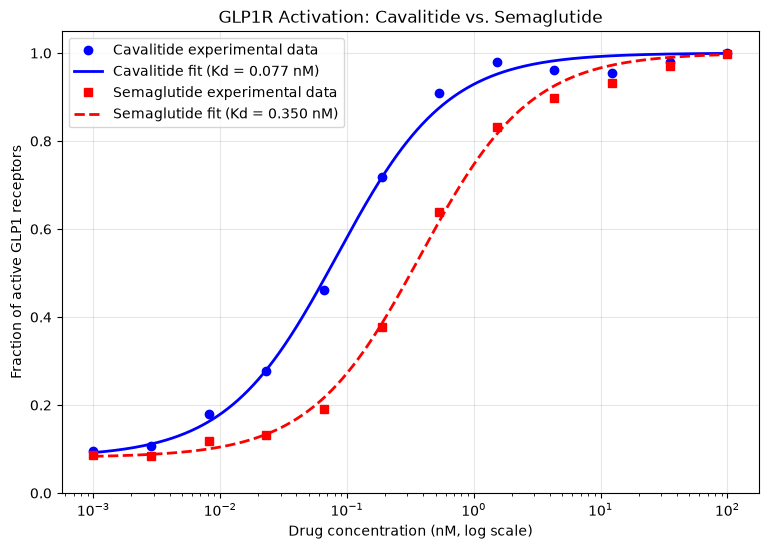

In [2]:

# Drug concentration range (nM)
L2 = np.logspace(-3, 2, 500)

plt.figure(figsize=(9, 6))

# Cavalitide experimental data and fitted curve
plt.semilogx(
    cavalitide_data[:, 0],
    cavalitide_data[:, 1],
    "o",
    color="blue",
    label="Cavalitide experimental data"
)

plt.semilogx(
    L2,
    Fact(L1, L2, Kd1, cav_Kd),
    "-",
    color="blue",
    linewidth=2,
    label=f"Cavalitide fit (Kd = {cav_Kd:.3f} nM)"
)

# Semaglutide experimental data and fitted curve
plt.semilogx(
    semaglutide_data[:, 0],
    semaglutide_data[:, 1],
    "s",
    color="red",
    label="Semaglutide experimental data"
)

plt.semilogx(
    L2,
    Fact(L1, L2, Kd1, sem_Kd),
    "--",
    color="red",
    linewidth=2,
    label=f"Semaglutide fit (Kd = {sem_Kd:.3f} nM)"
)

plt.xlabel("Drug concentration (nM, log scale)")
plt.ylabel("Fraction of active GLP1 receptors")
plt.title("GLP1R Activation: Cavalitide vs. Semaglutide")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("Task1_GLP1R_Binding.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
from scipy.stats import t as student_t

fig, ax = plt.subplots(figsize=(8, 4))

for name, data in [
    ("Cavalitide", cavalitide_data),
    ("Semaglutide", semaglutide_data)
]:
    x = data[:, 0]
    observed = data[:, 1]

    popt, pcov = curve_fit(
        lambda x, kd: Fact(0.015, x, 0.17, kd),
        x,
        observed,
        p0=[0.1],
        bounds=(0, np.inf)
    )

    kd = popt[0]
    predicted = Fact(0.015, x, 0.17, kd)
    residuals = observed - predicted
    rmse = np.sqrt(np.mean(residuals**2))

    # Approximate confidence interval from the fitted covariance.
    degrees_freedom = len(x) - 1
    standard_error = np.sqrt(pcov[0, 0])
    margin = (
        student_t.ppf(0.975, degrees_freedom) * standard_error
    )

    print(f"{name}:")
    print(f"  Fitted Kd: {kd:.6f} nM")
    print(
        f"  Approximate 95% confidence interval: "
        f"{kd - margin:.6f}–{kd + margin:.6f} nM"
    )
    print(f"  RMSE: {rmse:.5f}\n")

    ax.semilogx(x, residuals, "o-", label=name)

ax.axhline(0, color="gray", linestyle="--")
ax.set_xlabel("Drug concentration (nM)")
ax.set_ylabel("Observed minus predicted activation")
ax.set_title("Receptor-Model Residuals")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Fit Quality and Parameter Uncertainty

Cavalitide's fitted Kd was 0.07697 nM, with an approximate 95%
confidence interval of 0.06697–0.08697 nM. Semaglutide's fitted Kd
was 0.34980 nM, with an approximate interval of 0.30768–0.39193 nM.
These estimates support the conclusion that Cavalitide has greater
modeled receptor affinity under the same fitting assumptions.

The root mean squared error (RMSE) was 0.02073 for Cavalitide and
0.01921 for semaglutide, corresponding to approximately 2.07 and
1.92 percentage points of receptor activation. The residual plot
shows the direction and size of the errors at each concentration.
Positive residuals indicate underprediction; negative residuals
indicate overprediction.

The confidence intervals use a local approximation to the nonlinear
fit and assume independent errors with approximately constant
variance and normally distributed residuals. These assumptions
have not been established experimentally. The intervals describe
uncertainty in Kd within this model and do not include uncertainty
in endogenous GLP-1, other fixed parameters, or model structure.

Because the same data were used to fit and assess the model, these
results describe calibration quality rather than independent
biological validation.

### Results and Interpretation

For Cavalitide, the brute-force search estimated a dissociation constant of 0.0739 nM, while nonlinear least-squares fitting with SciPy's `curve_fit` produced a value of 0.0770 nM. The small difference is consistent with the limited resolution of the brute-force search, which tested 100 candidate values. The curve-fit estimate of **0.0770 nM** will be used in the subsequent PKPD model.

Applying the same fitting procedure to the semaglutide dataset produced a dissociation constant of **0.3498 nM**. This fitted estimate differs slightly from the 0.38 nM reference value used in the earlier semaglutide modeling exercise. Here, the comparison uses the fitted values for both drugs.

Semaglutide's fitted Kd is approximately **4.54 times** Cavalitide's fitted Kd. Because a lower Kd indicates greater receptor-binding affinity, Cavalitide has greater modeled affinity for GLP1R. Its concentration-response curve is shifted to the left, meaning that a lower Cavalitide concentration produces the same modeled receptor activation under the same endogenous GLP-1 conditions.

The plotted curves visually follow the experimental data, with sums of squared errors of approximately **0.00515 for Cavalitide** and **0.00443 for semaglutide**. These results support the model's description of the supplied concentration-response data.

A potential advantage of Cavalitide's greater affinity is that the desired receptor activation could be achieved at a lower free drug concentration. However, this does not by itself establish that a smaller administered dose would be sufficient, because drug exposure also depends on absorption, distribution, and elimination.

A potential dosing disadvantage is that using the same free drug concentration as semaglutide would produce higher modeled receptor activation, potentially exceeding the intended activation target. Cavalitide's dosing strategy may therefore require adjustment. This is a model-based consideration, not evidence that Cavalitide causes more adverse effects.

Finally, greater binding affinity does not establish greater clinical weight loss or improved safety. This simplified model treats receptor binding as activation and does not capture differences in signaling efficacy or clinical outcomes. Pharmacokinetics and dosing will be evaluated in Tasks 2 and 3.


### Application to the Combined PKPD Model

The fitted Cavalitide dissociation constant of 0.0770 nM will be incorporated into the combined pharmacokinetic-pharmacodynamic (PKPD) model in Task 3. By combining the receptor activation equation with simulated free drug concentrations in the bloodstream, we can predict how GLP1R activation changes over time following repeated dosing. This will allow us to investigate dosing adjustments needed to approach 90% receptor activation at steady state.


## Task 2: Simulate the pharmacokinetics of Cavalitide treatment
Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
# ===== choose product: 'Ozempic' or 'Wegovy' =====
#drug = 'Ozempic'
drug = 'Wegovy'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                                        depot='gut (oral)'),

    'Cavalitide': dict(Favailable=0.01,
                      ka=0.006,
                      D=21,
                      interval=24,
                      n_doses=100,
                      depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]


def simulate(D, n_doses, interval, dt):
    """Repeated dosing every interval h; returns time (h),
    depot amount (mg), and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))

    for i in range(n_doses):
        y[0] += Favailable * D
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)

        # Use solve_ivp instead of explicit Euler's method
        sol = solve_ivp(
            ODEfunc,
            (t_seg[0], t_seg[-1]),
            y,
            t_eval=t_seg
        )

        y_seg = sol.y

        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()

    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9

    return t, Asc_out, Cc_nM

We used the provided pharmacokinetic model and replaced the explicit Euler method with scipy.integrate.solve_ivp to solve the differential equations. This tracks the amount of drug in the depot and its concentration in the blood over time. We also defined the parameters for Ozempic, Wegovy, and Cavalitide, including their absorption rates, doses, and dosing intervals.

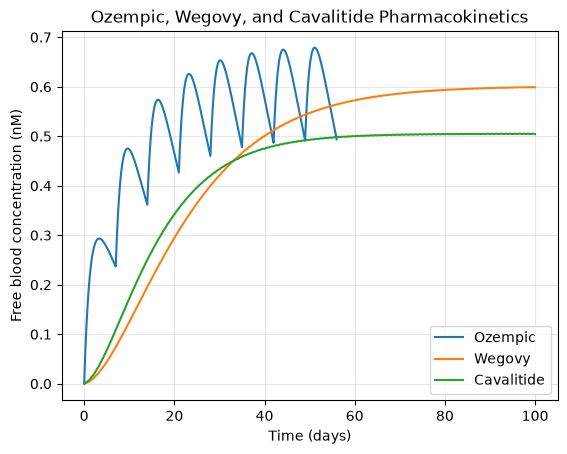

In [4]:
# --- compare Ozempic and Wegovy ---
plt.figure()

for drug in ['Ozempic', 'Wegovy', 'Cavalitide']:
    p = products[drug]
    Favailable = p['Favailable']
    ka = p['ka']

    t, Asc, Cc = simulate(
        p['D'],
        p['n_doses'],
        p['interval'],
        dt
    )

    plt.plot(t / 24, Ffree * Cc, label=drug)

plt.xlabel("Time (days)")
plt.ylabel("Free blood concentration (nM)")
plt.title("Ozempic, Wegovy, and Cavalitide Pharmacokinetics")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

We compared the blood concentrations of Ozempic, Wegovy, and Cavalitide over time. Ozempic had repeated peaks and decreases because it was given weekly, while Wegovy and Cavalitide increased more gradually because they were taken daily. Cavalitide reached steady state faster than Wegovy because it had a higher absorption rate. Since we reduced Cavalitide's dose to 21 mg, it also reached a lower steady state concentration.

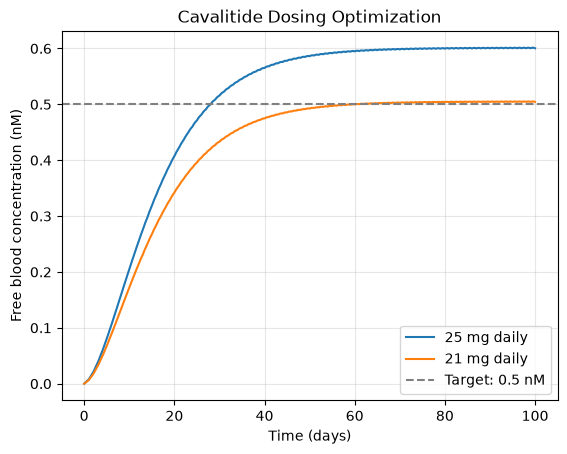

In [5]:
# --- compare original and optimized Cavalitide dosing ---
plt.figure()

for dose in [25, 21]:
    Favailable = products['Cavalitide']['Favailable']
    ka = products['Cavalitide']['ka']

    t, Asc, Cc = simulate(
        dose,
        products['Cavalitide']['n_doses'],
        products['Cavalitide']['interval'],
        dt
    )

    plt.plot(t / 24, Ffree * Cc, label=f"{dose} mg daily")

plt.axhline(y=0.5, color='gray', linestyle='--', label='Target: 0.5 nM')
plt.xlabel("Time (days)")
plt.ylabel("Free blood concentration (nM)")
plt.title("Cavalitide Dosing Optimization")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


We decreased the daily dose from 25 mg to 21 mg while keeping the dosing interval and absorption rate the same. We did this because the original dose gave us a steady state free blood concentration of about 0.6 nM, which was higher than our goal of 0.5 nM. After decreasing the dose to 21 mg, the concentration got closer to 0.5 nM, so we were able to reach our target.

## Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment



### Combined Pharmacokinetic–Pharmacodynamic Model

We combined the fitted receptor-binding model from Task 1 with the
Cavalitide pharmacokinetic model from Task 2. The initial regimen was
21 mg orally every 24 hours.

The pharmacokinetic parameters were unchanged: bioavailability = 0.01,
absorption rate = 0.006 h⁻¹, elimination rate = 0.0039 h⁻¹,
distribution volume = 10.8 L, molecular weight = 4113.6 g/mol,
and free fraction = 0.01.

The simulated total blood concentration was multiplied by the free
fraction to obtain free Cavalitide concentration. This free concentration
was then substituted into the receptor-activation equation:

$$
F_{act}(t)=
\frac{K_{d2}[GLP1]+K_{d1}[Cavalitide]_{free}(t)}
{K_{d1}K_{d2}+K_{d2}[GLP1]+K_{d1}[Cavalitide]_{free}(t)}
$$

Here, $K_{d1}=0.17$ nM, $[GLP1]=0.015$ nM, and $K_{d2}$ is the
full-precision Cavalitide Kd fitted in Task 1.

We simulated the first 100 days of treatment and adjusted only the dose
to achieve 90% average receptor activation during the final 24-hour
dosing cycle. We also calculated the minimum and maximum activation
because repeated dosing produces small fluctuations.

In [6]:
from scipy.optimize import brentq
from scipy.integrate import trapezoid

# Explicitly select Cavalitide parameters for the existing Task 2 functions.
# Those functions read these global variables.
Favailable = products["Cavalitide"]["Favailable"]  # 0.01
ka = products["Cavalitide"]["ka"]                  # 0.006 h^-1
ke = 0.0039
V = 10.8
MW = 4113.6
Ffree = 0.01

Kd1 = 0.17
L1 = 0.015
interval = 24
n_doses = 100
dt = 0.1
baseline_dose = 21.0

def final_cycle_stats(t, values):
    """Time-weighted mean, minimum, and maximum over the last 24 hours."""
    # The partner's simulate() repeats timestamps at dose boundaries.
    # Blood concentration is continuous, so retain one copy of each time.
    unique_t, indices = np.unique(t, return_index=True)
    unique_values = values[indices]

    mask = unique_t >= unique_t[-1] - interval
    cycle_t = unique_t[mask]
    cycle_values = unique_values[mask]

    mean = trapezoid(cycle_values, cycle_t) / (
        cycle_t[-1] - cycle_t[0]
    )
    return mean, cycle_values.min(), cycle_values.max()

# Baseline: partner's optimized Task 2 regimen.
t_base, depot_base, total_base = simulate(
    baseline_dose, n_doses, interval, dt
)
free_base = Ffree * total_base
activation_base = Fact(L1, free_base, Kd1, cav_Kd)

# In this linear PK model, concentration scales with administered dose.
# Use that relationship to find the dose giving 90% average activation.
def target_error(dose):
    predicted_free = free_base * dose / baseline_dose
    predicted_activation = Fact(L1, predicted_free, Kd1, cav_Kd)
    mean_activation = final_cycle_stats(
        t_base, predicted_activation
    )[0]
    return mean_activation - 0.90

optimized_dose = brentq(target_error, 0.0, 100.0)

# Run the actual PK simulation again with the optimized dose.
t_opt, depot_opt, total_opt = simulate(
    optimized_dose, n_doses, interval, dt
)
free_opt = Ffree * total_opt
activation_opt = Fact(L1, free_opt, Kd1, cav_Kd)

print(f"Fitted Cavalitide Kd: {cav_Kd:.8f} nM")
print(f"Optimized dose: {optimized_dose:.4f} mg every 24 hours")
print(
    f"Dose increase: "
    f"{100 * (optimized_dose / baseline_dose - 1):.2f}%"
)

for label, time, concentration, activation in [
    ("Task 2 baseline", t_base, free_base, activation_base),
    ("Task 3 optimized", t_opt, free_opt, activation_opt),
]:
    c_mean, c_min, c_max = final_cycle_stats(time, concentration)
    a_mean, a_min, a_max = final_cycle_stats(time, activation)

    print(f"\n{label}:")
    print(f"  Mean free concentration: {c_mean:.6f} nM")
    print(f"  Mean activation: {a_mean:.4%}")
    print(f"  Activation range: {a_min:.4%}–{a_max:.4%}")

Fitted Cavalitide Kd: 0.07696603 nM
Optimized dose: 28.5293 mg every 24 hours
Dose increase: 35.85%

Task 2 baseline:
  Mean free concentration: 0.504884 nM
  Mean activation: 86.9248%
  Activation range: 86.9121%–86.9311%

Task 3 optimized:
  Mean free concentration: 0.685903 nM
  Mean activation: 90.0000%
  Activation range: 89.9899%–90.0050%


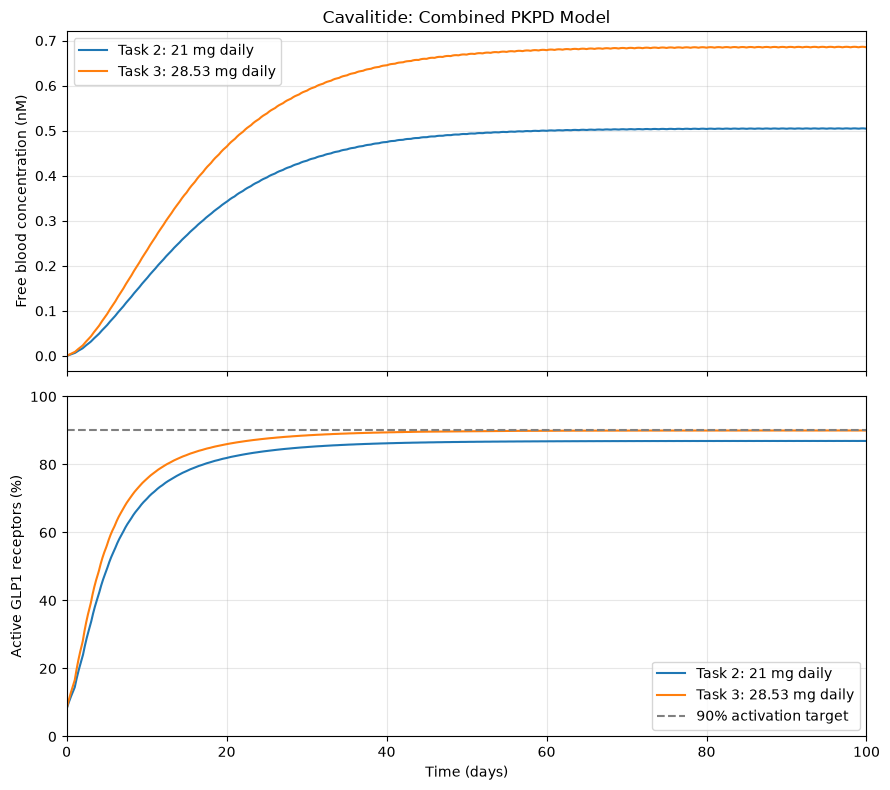

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True)

axes[0].plot(
    t_base / 24, free_base,
    label="Task 2: 21 mg daily"
)
axes[0].plot(
    t_opt / 24, free_opt,
    label=f"Task 3: {optimized_dose:.2f} mg daily"
)
axes[0].set_ylabel("Free blood concentration (nM)")
axes[0].set_title("Cavalitide: Combined PKPD Model")

axes[1].plot(
    t_base / 24, activation_base * 100,
    label="Task 2: 21 mg daily"
)
axes[1].plot(
    t_opt / 24, activation_opt * 100,
    label=f"Task 3: {optimized_dose:.2f} mg daily"
)
axes[1].axhline(
    90, color="gray", linestyle="--",
    label="90% activation target"
)
axes[1].set_xlabel("Time (days)")
axes[1].set_ylabel("Active GLP1 receptors (%)")
axes[1].set_ylim(0, 100)

for ax in axes:
    ax.set_xlim(0, 100)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig("Task3_PKPD.png", dpi=300, bbox_inches="tight")
plt.show()

### Results and Interpretation

The Task 2 regimen of 21 mg daily produced a final-cycle average free
Cavalitide concentration of approximately 0.5049 nM. This met the Task 2
concentration target but produced average receptor activation of
approximately 86.92%, below the Task 3 target of 90%.

Increasing the dose to approximately **28.53 mg every 24 hours** produced
an average free concentration of approximately **0.6859 nM** and average
receptor activation of **90.00%** during days 99–100. Activation ranged
from approximately **89.990% to 90.005%** during this final dosing cycle.

This adjustment increased the daily dose by approximately **35.85%**.
The dosing interval, absorption rate, bioavailability, elimination rate,
distribution volume, molecular weight, and free fraction remained
unchanged.

The predicted benefit is achieving sustained activation near the
assigned target while retaining the daily dosing schedule. However,
reaching 90% receptor activation does not demonstrate greater weight
loss or improved safety. Higher exposure could also affect tolerability,
which this model does not evaluate.

These predictions depend on the inherited pharmacokinetic assumptions,
including use of semaglutide's molecular weight and free fraction for
Cavalitide. Cavalitide-specific measurements and clinical validation
would be needed to assess the proposed regimen.

## Verification and Validation

We evaluated the analysis in two ways. Numerical verification
compared the simulated Cavalitide concentration with an exact
solution of the same differential equations. External validation
compared the semaglutide model's predicted exposure with published
clinical measurements.

For repeated dosing in this linear model, the average free
concentration at periodic steady state is:

$$
\overline{C}_{free}
=
\frac{F_{free} F D \times 10^6}
{MW\,V\,k_e\,\tau}
$$

Here, F is bioavailability, D is dose in mg, and τ is the dosing
interval in hours. The conversion factor gives concentration in nM.

For the external comparison, we used the oral semaglutide doses
and steady-state exposure measurements reported by
[Xie et al. (2024)](https://doi.org/10.1111/dom.15624).
We compared total concentration exposure over 24 hours, rather
than free concentration, to match the reported endpoint.

The model's exact steady-state total exposure over one interval is:

$$
AUC_{0-\tau,ss}
=
\frac{F D \times 10^6}{MW\,V\,k_e}
$$

This expression follows from mass balance over a complete dosing
cycle. Absorption rate affects the concentration profile but
cancels from the steady-state interval AUC in this model.

In [ ]:
# Numerical verification of the 21 mg daily Cavalitide simulation.
# Explicit constants avoid changing the simulation's global settings.
F_check = 0.01
ka_check = 0.006
ke_check = 0.0039
V_check = 10.8
MW_check = 4113.6
free_check = 0.01

# Exact repeated-dose solution, obtained by adding each dose's response.
exact_free = np.zeros_like(t_base)

for dose_time in np.arange(100) * 24.0:
    elapsed = t_base - dose_time
    mask = elapsed >= 0
    u = elapsed[mask]

    exact_free[mask] += (
        F_check * 21.0 * ka_check
        / (V_check * (ka_check - ke_check))
        * (np.exp(-ke_check * u) - np.exp(-ka_check * u))
        * 1e6 / MW_check * free_check
    )

max_error = np.max(np.abs(free_base - exact_free))
mean_simulated = final_cycle_stats(t_base, free_base)[0]

mean_exact = (
    free_check * F_check * 21.0 * 1e6
    / (MW_check * V_check * ke_check * 24)
)

relative_difference = (
    100 * abs(mean_simulated - mean_exact) / mean_exact
)

print("Numerical verification")
print(f"Maximum error versus exact solution: {max_error:.3e} nM")
print(f"Final-day simulated mean: {mean_simulated:.6f} nM")
print(f"Asymptotic steady-state mean: {mean_exact:.6f} nM")
print(f"Relative difference: {relative_difference:.4f}%")

assert max_error < 1e-5
assert abs(mean_simulated - mean_exact) / mean_exact < 0.001
assert np.all((activation_opt >= 0) & (activation_opt <= 1))

# Published total semaglutide AUC values from Xie et al. (2024).
study_doses = np.array([3.0, 7.0, 14.0])
published_auc = np.array([233.0, 552.0, 1288.0])

# Model predictions at the same doses; no free-fraction multiplier.
model_auc = (
    F_check * study_doses * 1e6
    / (MW_check * V_check * ke_check)
)

print("\nOral semaglutide steady-state total AUC (nM·h)")
print("Dose (mg) | Model | Published | Difference (%)")

for dose, predicted, observed in zip(
    study_doses, model_auc, published_auc
):
    difference = 100 * (predicted - observed) / observed
    print(
        f"{dose:9.0f} | {predicted:5.1f} | "
        f"{observed:9.1f} | {difference:14.1f}"
    )

### Verification and Validation Results

The numerical simulation agreed with the exact repeated-dose
solution to within approximately 7 × 10⁻⁹ nM. For 21 mg daily,
the simulated average free concentration during days 99–100 was
0.504884 nM, compared with an asymptotic analytical value of
0.505007 nM. The approximately 0.0245% difference is consistent
with the simulation being close to, but not exactly at, periodic
steady state. These checks support the numerical implementation.

For an external comparison, Xie et al. (2024) reported steady-state
oral semaglutide exposure in healthy Chinese adults. At daily
doses of 3, 7, and 14 mg, our model predicted total 24-hour AUC
values of 173.1, 404.0, and 808.0 nM·h, compared with published
values of 233, 552, and 1288 nM·h. The model therefore
underpredicted exposure by approximately 25.7%, 26.8%, and 37.3%.

The model captures increasing exposure with dose, but its
quantitative disagreement limits confidence in clinical dose
predictions. Fixed bioavailability, clearance, and distribution
parameters may not represent the study population and dosing
conditions. This comparison does not identify which parameter
caused the discrepancy.

We retained the assignment parameters rather than adjusting them
to force agreement. This is a limited external check of the
semaglutide-based PK model, not direct validation of Cavalitide,
its receptor activation, or the proposed 28.53 mg daily regimen.

## Conclusions:

Cavalitide showed greater modeled affinity for GLP1R than
semaglutide, with fitted Kd values of approximately 0.0770 and
0.3498 nM, respectively. This approximately 4.54-fold difference
indicates that Cavalitide can achieve comparable modeled receptor
activation at a lower free concentration.

The pharmacokinetic model predicted that 21 mg daily would produce
approximately 0.505 nM free Cavalitide and 86.92% receptor
activation near day 100. Increasing only the daily dose to
approximately 28.53 mg achieved 90% average activation during
the final dosing cycle.

Numerical verification showed close agreement between the
simulation and the exact mathematical solution. However, comparison
with published oral semaglutide measurements showed that the model
underpredicted exposure by approximately 26–37%. Therefore,
accurate numerical implementation does not establish that the
model accurately predicts clinical exposure.

Cavalitide's modeled affinity supports further investigation, but
these results do not establish superiority to oral or injected
semaglutide in weight loss, safety, or required administered dose.
The next priority would be to measure Cavalitide-specific
pharmacokinetic properties and validate exposure and response
predictions before using the model to guide clinical dosing.

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:

We used ChatGPT and Codex to help with the Task 1 fitting code and
combine the pharmacokinetic and receptor-binding models for Task 3.
AI also helped troubleshoot errors, add confidence intervals and
numerical checks, find a published study for comparison, and draft
explanations of the results. It was useful for organizing the
analysis and identifying limitations in the model.

## GitHub Repository Link:

https://github.com/aymen-akram/BME2315_Module3 


## References:

Centers for Disease Control and Prevention. (2025, December 4). How overweight and obesity impacts your health. https://www.cdc.gov/healthy-weight-growth/food-activity/overweight-obesity-impacts-health.html

National Institute of Diabetes and Digestive and Kidney Diseases. (n.d.). Prescription medications to treat overweight & obesity. https://www.niddk.nih.gov/health-information/weight-management/prescription-medications-treat-overweight-obesity

Wilding, J. P. H., et al. (2021). Once-weekly semaglutide in adults with overweight or obesity. New England Journal of Medicine, 384(11), 989–1002. https://doi.org/10.1056/NEJMoa2032183

Wilding, J. P. H., et al. (2022). Weight regain and cardiometabolic effects after withdrawal of semaglutide: The STEP 1 trial extension. Diabetes, Obesity and Metabolism, 24(8), 1553–1564. https://doi.org/10.1111/dom.14725

Xie, P., Abildlund, M. T., Bækdal, T. A., He, X., Lyauk, Y. K.,
Patted, U. R. H., Ning, Z., & Shi, A. (2024). A phase 1, randomized,
double-blind, placebo-controlled trial investigating the
pharmacokinetics, pharmacodynamics, safety and tolerability of oral
semaglutide in healthy Chinese subjects. *Diabetes, Obesity and
Metabolism, 26*(8), 3068–3077. https://doi.org/10.1111/dom.15624

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*